# 03 — Stability of the inverse indices

Which other series, multiplied by a nearly constant factor, stay closest to the H100 on-demand price?

On dates where \(i_{t,k} = P_{0,t} / P_{k,t}\) exists:

* **Absolute.** Mean distance of \(i\) from its own median, and the mean absolute change between adjacent days.
* **Relative.** Those distances divided by the level of \(i\), and the standard deviation of adjacent-day log changes (`log_vol`).

A series is ranked only if it covers at least 75% of the baseline dates and has at least 30 observations. Same-card plans are ranked apart from other cards.

One mechanical result is easy to miss. If \(P_k\) never changes, then \(i_{t,k}\) is just a rescaled copy of \(P_{0,t}\), so its log-volatility equals the baseline's own log-volatility. Nothing in this sample comes out *below* that floor: no other price moved with H100 on-demand closely enough to cancel its changes. The series tied on the floor are the ones with a single posted price. They are the least-changing indices, and they are tied with each other.


In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from icx.indices import load_matrix, load_vector
from icx.runtime import require_project_venv
from icx.stability import load_scores, ranked, sync_stability
from icx.store import Decision, open_store

ROOT = require_project_venv()
layout = open_store(ROOT)
baseline = layout.baseline
print(f"Project:  {ROOT}")
print(f"Python:   {sys.executable}")
print(f"Baseline: {baseline.key}")


Project:  /home/neoabs/src/gka/ICX
Python:   /home/neoabs/src/gka/ICX/.venv/bin/python
Baseline: nvidia-h100__ON_DEMAND


In [2]:
built = sync_stability(layout)
scores = built.frame
print(f"Build:    {built.decision.value}  series={len(scores):,}  upserted={built.rows_upserted}")
again = sync_stability(layout)
print(f"Second:   {again.decision.value}")
if again.decision is not Decision.SKIP:
    raise RuntimeError("Unchanged indices should reuse the stored scores.")

vector = load_vector(layout)
ordered = vector.copy()
ordered["date"] = pd.to_datetime(ordered["date"])
ordered = ordered.sort_values("date")
adjacent = ordered["date"].diff().dt.days.eq(1)
baseline_vol = float(np.log(ordered["index_value"]).diff().loc[adjacent].std(ddof=1))
print(f"Baseline log-volatility: {baseline_vol:.6f}")

scores["log_vol"] = pd.to_numeric(scores["log_vol"])
scores["n_unique_prices"] = pd.to_numeric(scores["n_unique_prices"])
eligible = scores.loc[scores["eligible"].astype(bool)].copy()
floor = eligible["log_vol"].min()
on_floor = eligible.loc[(eligible["log_vol"] - floor).abs() < 1e-6]
print(f"Eligible series: {len(eligible)}")
print(f"Tied on the volatility floor: {len(on_floor)}")
print(f"Of those, prices that never change: {int((on_floor['n_unique_prices'] == 1).sum())}")
print(f"Eligible series below the floor: {int((eligible['log_vol'] < baseline_vol * 0.99).sum())}")


Build:    full  series=273  upserted=273
Second:   skip
Baseline log-volatility: 0.016781
Eligible series: 194
Tied on the volatility floor: 7
Of those, prices that never change: 7
Eligible series below the floor: 0


In [3]:
columns = ["series", "n", "n_unique_prices", "abs_dev", "rel_dev", "mean_abs_change", "mean_rel_change", "log_vol"]
same = ranked(scores, "same_card")
other = ranked(scores, "other_card")
print("Same card, other plans")
print(same[columns].to_string(index=False))
print()
print("Other cards, lowest log-volatility")
print(other[columns].head(12).to_string(index=False))


Same card, other plans
                  series   n  n_unique_prices  abs_dev  rel_dev  mean_abs_change  mean_rel_change  log_vol
     nvidia-h100__CUSTOM 131                1 0.067383 0.041390         0.014005         0.008641 0.016911
       nvidia-h100__SPOT 132               18 0.108355 0.062217         0.024881         0.013971 0.024524
nvidia-h100__RESERVATION 132               57 0.052655 0.045287         0.033283         0.028920 0.042683

Other cards, lowest log-volatility
                          series   n  n_unique_prices  abs_dev  rel_dev  mean_abs_change  mean_rel_change  log_vol
         nvidia-p6000__ON_DEMAND 132                1 0.115841 0.041414         0.023695         0.008509 0.016781
         nvidia-v100s__ON_DEMAND 132                1 0.144802 0.041414         0.029619         0.008509 0.016781
         nvidia-m4000__ON_DEMAND 132                1 0.283168 0.041414         0.057922         0.008509 0.016781
           nvidia-k80__ON_DEMAND 132                1

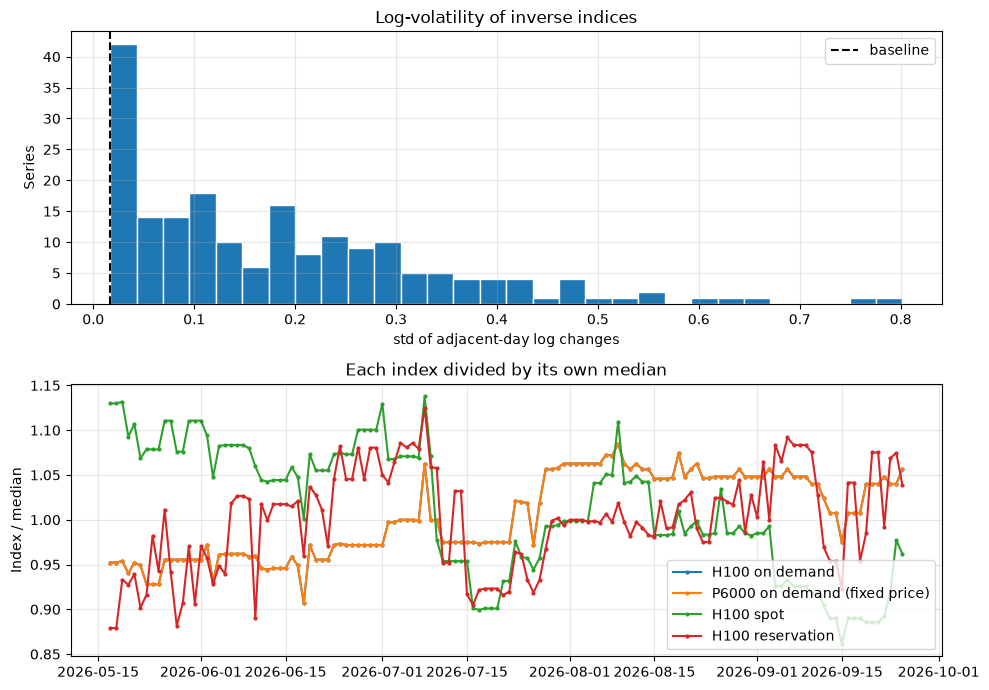

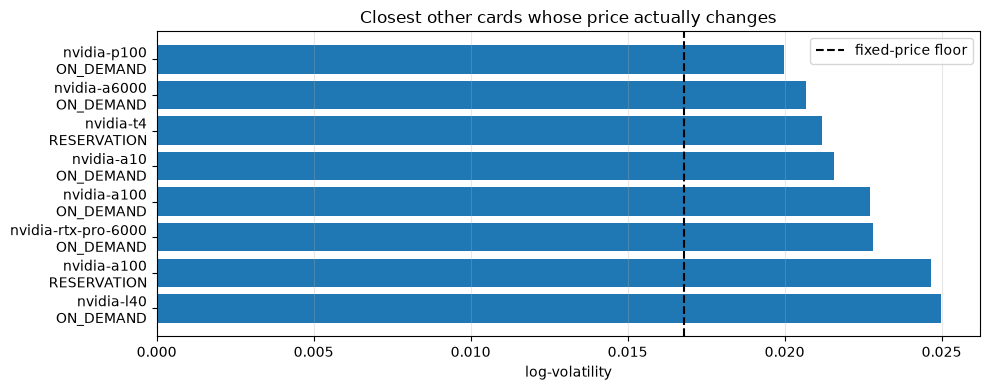

In [4]:
matrix = load_matrix(layout)

def normalized(dates, values) -> pd.DataFrame:
    frame = pd.DataFrame({"date": pd.to_datetime(dates), "value": pd.to_numeric(values)})
    frame = frame.dropna().sort_values("date")
    frame["value"] = frame["value"] / frame["value"].median()
    rows = []
    previous = None
    for row in frame.itertuples(index=False):
        if previous is not None and (row.date - previous).days > 1:
            rows.append({"date": previous + pd.Timedelta(days=1), "value": np.nan})
        rows.append({"date": row.date, "value": row.value})
        previous = row.date
    return pd.DataFrame(rows)

def plot_series(axis, dates, values, label):
    line = normalized(dates, values)
    axis.plot(line["date"], line["value"], label=label, marker="o", ms=2)

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
axes[0].hist(eligible["log_vol"], bins=30, color="tab:blue", edgecolor="white")
axes[0].axvline(baseline_vol, color="black", ls="--", label="baseline")
axes[0].set_title("Log-volatility of inverse indices")
axes[0].set_xlabel("std of adjacent-day log changes")
axes[0].set_ylabel("Series")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

plot_series(axes[1], ordered["date"], ordered["index_value"], "H100 on demand")
sticky = "nvidia-p6000__ON_DEMAND"
sticky_rows = matrix.loc[matrix["series"] == sticky]
plot_series(axes[1], sticky_rows["date"], sticky_rows["index_value"], "P6000 on demand (fixed price)")
for series, label in [
    ("nvidia-h100__SPOT", "H100 spot"),
    ("nvidia-h100__RESERVATION", "H100 reservation"),
]:
    rows = matrix.loc[matrix["series"] == series]
    plot_series(axes[1], rows["date"], rows["index_value"], label)
axes[1].set_title("Each index divided by its own median")
axes[1].set_ylabel("Index / median")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

moving = other.loc[other["n_unique_prices"] >= 5].head(8)
fig, axis = plt.subplots(figsize=(10, 4))
labels = [series.replace("__", "\n") for series in moving["series"]]
axis.barh(labels[::-1], moving["log_vol"].to_numpy()[::-1], color="tab:blue")
axis.axvline(baseline_vol, color="black", ls="--", label="fixed-price floor")
axis.set_xlabel("log-volatility")
axis.set_title("Closest other cards whose price actually changes")
axis.legend()
axis.grid(True, axis="x", alpha=0.3)
fig.tight_layout()
plt.show()
